# 03 · B1: quan el símptoma apunta a la bateria, ho és?

Dels mòbils que arriben amb un símptoma típic de bateria (no carrega, dura poc, no s'encén, inflada), quina avaria hi van trobar els voluntaris?

- Només MobiFix: el tipus d'avaria l'han posat persones, no el classificador.
- Els símptomes es detecten amb paraules clau (`comu.SIMPTOMES`). Molts textos ja inclouen el diagnòstic ("bateria canviada"), i això infla la bateria. Per això ho mirem també només amb els textos que **no** diuen "bateria".

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import comu

rng = np.random.default_rng(42)

# Tipus d'avaria més detallat que comu.GRUPS: aquí volem separar bateria, carregador i port
DETALL = {"Power/battery": "Bateria", "Charger": "Carregador", "USB/charging port": "Port de càrrega",
          "Screen": "Pantalla", "Unknown": "Desconegut"}
PROGRAMARI = {"Software update", "Software issue", "Stuck booting", "Storage problem",
              "Help/configuration", "Performance", "Access issue"}

mobifix = comu.carrega_mobifix()
mobifix = mobifix[mobifix["problem"].notna()].copy()
mobifix["avaria"] = mobifix["fault_type"].map(DETALL)
mobifix.loc[mobifix["fault_type"].isin(PROGRAMARI), "avaria"] = "Programari"
mobifix["avaria"] = mobifix["avaria"].fillna("Altres")
s = comu.simptomes(mobifix["problem"])
mobifix = pd.concat([mobifix, s], axis=1)
print(f"Reparacions de MobiFix amb text: {len(mobifix):,}")
s.sum()

Reparacions de MobiFix amb text: 1,664


no_carrega         52
dura_poc           10
no_sencen          50
inflada             4
algun_simptoma    114
mencio_bateria    187
dtype: int64

## Quina avaria hi ha darrere de cada símptoma

In [2]:
ORDRE = ["Bateria", "Carregador", "Port de càrrega", "Programari", "Pantalla", "Altres", "Desconegut"]

def darrere(df):
    files = {}
    for nom in list(comu.SIMPTOMES) + ["algun_simptoma"]:
        sub = df[df[nom]]
        files[nom] = sub["avaria"].value_counts(normalize=True).reindex(ORDRE, fill_value=0)
        files[nom]["n"] = len(sub)
    return pd.DataFrame(files).T

tots = darrere(mobifix)
sense_diagnostic = darrere(mobifix[~mobifix["mencio_bateria"]])
print("Tots els textos amb el símptoma:")
display(tots.round(2))
print("Només els que no diuen 'bateria' (sense el diagnòstic del voluntari):")
sense_diagnostic.round(2)

Tots els textos amb el símptoma:


avaria,Bateria,Carregador,Port de càrrega,Programari,Pantalla,Altres,Desconegut,n
no_carrega,0.56,0.04,0.31,0.00,0.02,0.00,0.08,52.0
dura_poc,0.80,0.00,0.00,0.00,0.10,0.10,0.00,10.0
no_sencen,0.64,0.02,0.00,0.08,0.06,0.06,0.14,50.0
inflada,1.00,0.00,0.00,0.00,0.00,0.00,0.00,4.0
algun_simptoma,0.62,0.03,0.14,0.04,0.04,0.04,0.10,114.0


Només els que no diuen 'bateria' (sense el diagnòstic del voluntari):


avaria,Bateria,Carregador,Port de càrrega,Programari,Pantalla,Altres,Desconegut,n
no_carrega,0.50,0.05,0.33,0.00,0.02,0.00,0.10,42.0
dura_poc,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
no_sencen,0.57,0.02,0.00,0.10,0.07,0.07,0.17,42.0
inflada,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
algun_simptoma,0.53,0.04,0.17,0.05,0.05,0.04,0.13,83.0


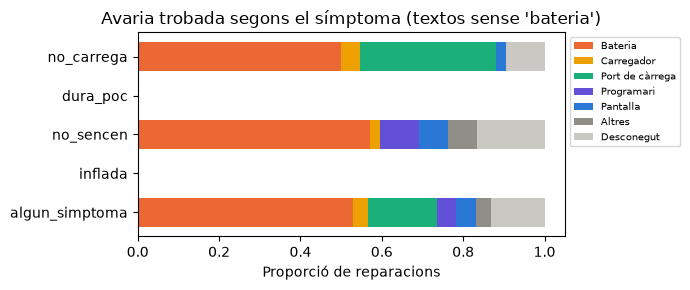

In [3]:
def barres(t, titol):
    t = t.drop(columns="n")
    ax = t.plot.barh(stacked=True, figsize=(7, 3), width=0.75,
                     color=["#eb6834", "#eda100", "#1baf7a", "#6250d6", "#2a78d6", "#8f8e89", "#c9c8c2"])
    ax.set_xlabel("Proporció de reparacions"); ax.set_title(titol)
    ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); ax.invert_yaxis()
    plt.tight_layout(); plt.show()

barres(sense_diagnostic, "Avaria trobada segons el símptoma (textos sense 'bateria')")

## Comprovació a mà de les paraules clau

Una mostra de 30 textos amb algun símptoma: cal llegir-los i comprovar que el símptoma detectat és correcte.

In [4]:
cols = list(comu.SIMPTOMES) + ["avaria", "problem"]
mostra = mobifix[mobifix["algun_simptoma"]].sample(30, random_state=42)[cols]
with pd.option_context("display.max_colwidth", 120):
    display(mostra)

,no_carrega,dura_poc,no_sencen,inflada,avaria,problem
1450,False,False,True,False,Bateria,Nach einem Sturz zeigte ein „S60“ Smartphone von Doogee auf einmal keine Funktion mehr. Es ließ sich nicht einschalt...
55,True,False,False,False,Port de càrrega,Doesn't charge
680,True,False,False,False,Bateria,Accu laadt niet op ~ Loszittende accu
1219,False,False,True,False,Desconegut,Won't turn on
124,True,False,True,False,Bateria,Not charging. won't turn on. Advice given.
809,False,True,False,False,Bateria,batterij loop snel leeg ~ ouderdom
1249,False,False,True,False,Bateria,Doesn't turn on: tested and it charges. Opened it: the power button is very hard to press but everything works.
1158,True,False,False,False,Bateria,Does not charge plus other damage
849,False,True,False,False,Bateria,Battery drains really fast
139,True,False,False,False,Bateria,"Doesn't charge, doesn't switch on. Needs new battery."
